In [1]:
# 2026 U.S. Senate Campaign Fundraising and Spending

# Research question:
# How did reported campaign fundraising and spending compare among 2026 U.S. Senate candidates in Iowa, Michigan, Ohio and Texas?


# The analysis uses candidate financial totals from the FEC OpenFEC API. The data was collected on November 8, 2026.

In [4]:
from pathlib import Path
import pandas as pd

data_path = Path("data/processed/fec_2026_senate_clean.csv")

if not data_path.exists():
    data_path = Path("../data/processed/fec_2026_senate_clean.csv")

senate = pd.read_csv(data_path)

print("Rows and columns:", senate.shape)
display(senate.head())
print("Columns:", senate.columns.tolist())

Rows and columns: (94, 13)


,candidate_id,candidate_name,party_code,party_name,state,office,receipts,disbursements,cash_on_hand,debts_owed,coverage_start_date,coverage_end_date,last_filing_date
0,S6IA00306,"HENRY, CHRIS",DEM,DEMOCRATIC PARTY,IA,S,0.00,0.00,0.00,0.00,NaN,NaN,2025-08-29
1,S6IA00280,"NORRIS, JACKIE",DEM,DEMOCRATIC PARTY,IA,S,363563.01,363563.01,0.00,0.00,2025-07-01,2026-03-20,2025-08-05
2,S6IA00256,"SAGE, NATHAN",DEM,DEMOCRATIC PARTY,IA,S,1433543.65,1433534.77,8.88,6821.92,2025-04-01,2026-09-30,2025-04-15
3,S6IA00264,"SCHOLTEN, JAMES",DEM,DEMOCRATIC PARTY,IA,S,213415.45,205271.15,8144.30,10100.00,2025-04-01,2025-12-31,2025-06-03
4,S6IA00298,"TUREK, JOSHUA",DEM,DEMOCRATIC PARTY,IA,S,24290521.10,21217670.10,3072851.00,0.00,2025-07-01,2026-10-14,2026-11-06


Columns: ['candidate_id', 'candidate_name', 'party_code', 'party_name', 'state', 'office', 'receipts', 'disbursements', 'cash_on_hand', 'debts_owed', 'coverage_start_date', 'coverage_end_date', 'last_filing_date']


In [5]:
# I checked how many candidate records I have for each state and whether anything is missing or duplicated.

In [6]:
print(senate.shape)
print(senate["state"].value_counts().sort_index())
print(senate.isna().sum())
print("Duplicate candidate IDs:", senate["candidate_id"].duplicated().sum())

(94, 13)
state
IA    12
MI    25
OH    16
TX    41
Name: count, dtype: int64
candidate_id            0
candidate_name          0
party_code              0
party_name              1
state                   0
office                  0
receipts                0
disbursements           0
cash_on_hand            0
debts_owed              0
coverage_start_date    45
coverage_end_date      45
last_filing_date        1
dtype: int64
Duplicate candidate IDs: 0


In [7]:
# I compared the median receipts and spending for candidates in each state.

In [8]:
state_summary = senate.groupby("state").agg({
    "candidate_id": "count",
    "receipts": "median",
    "disbursements": "median"
})

state_summary = state_summary.rename(columns={
    "candidate_id": "candidate_records",
    "receipts": "median_receipts",
    "disbursements": "median_disbursements"
})

display(state_summary)

,candidate_records,median_receipts,median_disbursements
state,,,
IA,12,288489.23,284417.08
MI,25,0.00,0.00
OH,16,3803.31,3707.02
TX,41,0.00,0.00


In [9]:
# Some records have zero receipts or spending, so I also checked the candidates with positive reported amounts.

In [10]:
receipts_by_state = senate[senate["receipts"] > 0].groupby("state")["receipts"].agg(["count", "median"])
receipts_by_state.columns = ["records_with_receipts", "median_receipts"]
display(receipts_by_state)

disbursements_by_state = senate[senate["disbursements"] > 0].groupby("state")["disbursements"].agg(["count", "median"])
disbursements_by_state.columns = ["records_with_spending", "median_disbursements"]
display(disbursements_by_state)

,records_with_receipts,median_receipts
state,,
IA,8,963981.890
MI,12,163357.495
OH,9,55255.700
TX,16,12961.425


,records_with_spending,median_disbursements
state,,
IA,8,961344.34
MI,12,162088.19
OH,9,50857.72
TX,16,12301.19


In [11]:
# Among records with positive totals, Iowa had the highest median receipts ($963,981.89) and spending ($961,344.34). Texas had the 
# lowest median receipts ($12,961.43) and spending ($12,301.19). Michigan Ohio were in between. The median receipts and spending were 
# close in each state. This comparison only includes records with positive totals.

In [12]:
# Comparing by party
# I compared receipts and spending by state and party. These medians only include records with positive totals.

In [13]:
party_receipts = senate[senate["receipts"] > 0].groupby(
    ["state", "party_name"]
)["receipts"].agg(["count", "median"]).round(2)

party_receipts.columns = ["records_with_receipts", "median_receipts"]
display(party_receipts)

party_spending = senate[senate["disbursements"] > 0].groupby(
    ["state", "party_name"]
)["disbursements"].agg(["count", "median"]).round(2)

party_spending.columns = ["records_with_spending", "median_disbursements"]
display(party_spending)

records_with_receipts  median_receipts
state party_name                                                  
IA    DEMOCRATIC PARTY                          4        898553.33
      LIBERTARIAN PARTY                         1         83667.19
      REPUBLICAN PARTY                          3       6964047.10
MI    DEMOCRATIC PARTY                          6       9650013.16
      LIBERTARIAN PARTY                         1          7159.28
      NO PARTY AFFILIATION                      1          1000.00
      REPUBLICAN PARTY                          4         80167.22
OH    DEMOCRATIC PARTY                          5         46808.59
      INDEPENDENT                               2         67990.69
      LIBERTARIAN PARTY                         1         55255.70
      REPUBLICAN PARTY                          1      19894785.94
TX    DEMOCRATIC PARTY                          4       9363837.23
      INDEPENDENT                               1         18959.79
      LIBERTARIAN PARTY                         2         12961.42
      REPUBLICAN PARTY                          8         10390.62
      WRITE-IN                                  1          5430.00

records_with_spending  median_disbursements
state party_name                                                       
IA    DEMOCRATIC PARTY                          4             898548.89
      LIBERTARIAN PARTY                         1              74632.11
      REPUBLICAN PARTY                          3            5690659.94
MI    DEMOCRATIC PARTY                          6            7048622.42
      LIBERTARIAN PARTY                         1               5035.32
      NO PARTY AFFILIATION                      1                220.48
      REPUBLICAN PARTY                          4              76999.89
OH    DEMOCRATIC PARTY                          5              50857.72
      INDEPENDENT                               2              55584.96
      LIBERTARIAN PARTY                         1              47000.44
      REPUBLICAN PARTY                          1           15655689.37
TX    AMERICAN PARTY                            1                328.22
      DEMOCRATIC PARTY                          4            9435703.58
      INDEPENDENT                               1              17363.76
      LIBERTARIAN PARTY                         2              12301.19
      REPUBLICAN PARTY                          7              11438.76
      WRITE-IN                                  1               5352.30

In [14]:
top_spenders = senate[
    senate["party_code"].isin(["DEM", "REP"])
    & (senate["disbursements"] > 0)
].sort_values("disbursements", ascending=False)

top_spenders = top_spenders.groupby(
    ["state", "party_code"]
).head(1)

top_spenders = top_spenders.sort_values(["state", "party_code"])

display(top_spenders[[
    "state",
    "candidate_name",
    "party_name",
    "receipts",
    "disbursements"
]])

,state,candidate_name,party_name,receipts,disbursements
4,IA,"TUREK, JOSHUA",DEMOCRATIC PARTY,2.429052e+07,2.121767e+07
7,IA,"ARENHOLZ, ASHLEY HINSON",REPUBLICAN PARTY,1.414797e+07,1.390306e+07
12,MI,"EL-SAYED, ABDUL",DEMOCRATIC PARTY,5.383087e+07,5.109684e+07
30,MI,"ROGERS, MICHAEL J",REPUBLICAN PARTY,2.301644e+07,1.936964e+07
37,OH,"BROWN, SHERROD",DEMOCRATIC PARTY,6.840920e+07,6.395640e+07
51,OH,"HUSTED, JON",REPUBLICAN PARTY,1.989479e+07,1.565569e+07
59,TX,"TALARICO, JAMES",DEMOCRATIC PARTY,1.463499e+08,1.364271e+08
84,TX,"PAXTON, WARREN KENNETH JR.",REPUBLICAN PARTY,2.232747e+07,1.754307e+07


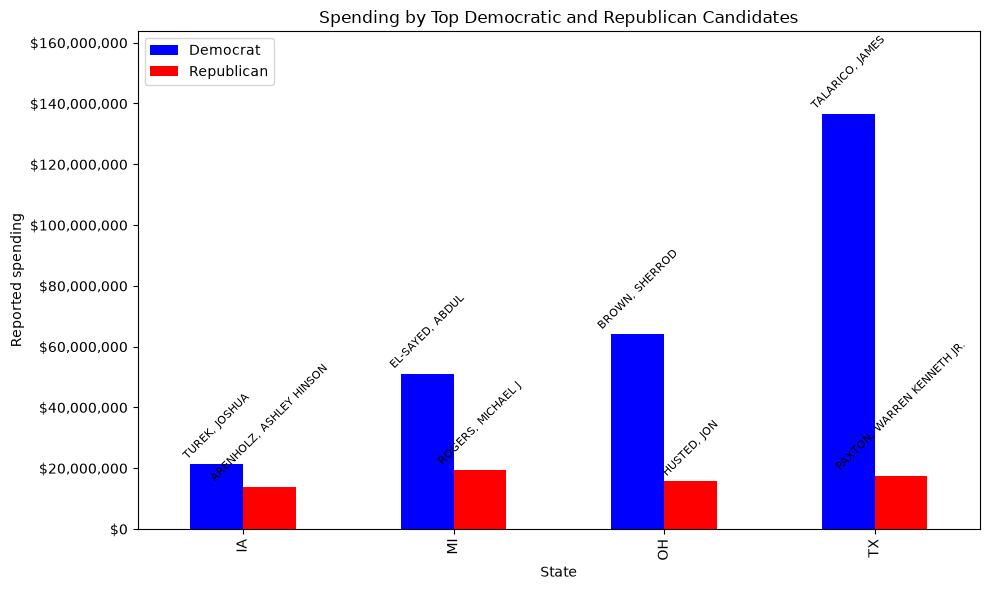

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

states = ["IA", "MI", "OH", "TX"]
parties = ["DEM", "REP"]

spending_chart = top_spenders.pivot(
    index="state",
    columns="party_code",
    values="disbursements"
).reindex(index=states, columns=parties)

ax = spending_chart.plot(
    kind="bar",
    color=["blue", "red"],
    figsize=(10, 6)
)

ax.set_title("Spending by Top Democratic and Republican Candidates")
ax.set_xlabel("State")
ax.set_ylabel("Reported spending")
ax.yaxis.set_major_formatter(FuncFormatter(lambda amount, position: f"${amount:,.0f}"))
ax.legend(["Democrat", "Republican"])
ax.margins(y=0.2)

for bars, party in zip(ax.containers, parties):
    for bar, state in zip(bars, states):
        candidate = top_spenders[
            (top_spenders["state"] == state)
            & (top_spenders["party_code"] == party)
        ]["candidate_name"]

        if len(candidate) > 0:
            ax.annotate(
                candidate.iloc[0],
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                rotation=45,
                fontsize=8
            )

Path("figures").mkdir(exist_ok=True)
plt.tight_layout()
plt.savefig("figures/party_spending_by_state.png", dpi=300)
plt.show()

In [16]:
from getpass import getpass

FEC_API_KEY = getpass("Enter your FEC API key: ")
print("FEC key loaded:", bool(FEC_API_KEY))

Enter your FEC API key:  ········


FEC key loaded: True


In [17]:
import requests
outside_url = "https://api.open.fec.gov/v1/schedules/schedule_e/by_candidate/"
outside_records = []
headers = {"X-Api-Key": FEC_API_KEY}

for candidate_id in top_spenders["candidate_id"].dropna().unique():
    params = {
        "cycle": 2026,
        "candidate_id": candidate_id,
        "per_page": 100
    }

    response = requests.get(
        outside_url,
        params=params,
        headers=headers,
        timeout=30
    )
    response.raise_for_status()

    outside_records.extend(response.json()["results"])

outside = pd.json_normalize(outside_records)

print("Rows and columns:", outside.shape)
print("Columns:", outside.columns.tolist())
display(outside.head())

Rows and columns: (364, 8)
Columns: ['candidate_id', 'candidate_name', 'committee_id', 'committee_name', 'count', 'cycle', 'support_oppose_indicator', 'total']


,candidate_id,candidate_name,committee_id,committee_name,count,cycle,support_oppose_indicator,total
0,S6IA00298,"TUREK, JOSHUA",C00418897,VOTEVETS,40,2026,S,9756436.14
1,S6IA00298,"TUREK, JOSHUA",C00528455,INTERNATIONAL ALLIANCE OF THEATRICAL STAGE EMP...,1,2026,S,1097.21
2,S6IA00298,"TUREK, JOSHUA",C00571703,SLF PAC,41,2026,O,23249833.39
3,S6IA00298,"TUREK, JOSHUA",C00580068,PROGRESSIVE TURNOUT PROJECT,2,2026,S,43722.38
4,S6IA00298,"TUREK, JOSHUA",C00640300,ACTIVATE AMERICA,3,2026,S,1683.21


In [18]:
outside_summary = outside.pivot_table(
    index="candidate_id",
    columns="support_oppose_indicator",
    values="total",
    aggfunc="sum",
    fill_value=0
).reset_index()

outside_summary = outside_summary.rename(columns={
    "S": "outside_support",
    "O": "outside_opposition"
})

for column in ["outside_support", "outside_opposition"]:
    if column not in outside_summary.columns:
        outside_summary[column] = 0

candidate_money = top_spenders[[
    "candidate_id",
    "state",
    "candidate_name",
    "party_name",
    "receipts",
    "disbursements"
]].merge(outside_summary, on="candidate_id", how="left")

candidate_money[["outside_support", "outside_opposition"]] = (
    candidate_money[["outside_support", "outside_opposition"]].fillna(0)
)

display(candidate_money[[
    "state",
    "candidate_name",
    "party_name",
    "receipts",
    "disbursements",
    "outside_support",
    "outside_opposition"
]].round(2))

,state,candidate_name,party_name,receipts,disbursements,outside_support,outside_opposition
0,IA,"TUREK, JOSHUA",DEMOCRATIC PARTY,2.429052e+07,2.121767e+07,11807948.68,3.306242e+07
1,IA,"ARENHOLZ, ASHLEY HINSON",REPUBLICAN PARTY,1.414797e+07,1.390306e+07,7304823.64,2.254477e+07
2,MI,"EL-SAYED, ABDUL",DEMOCRATIC PARTY,5.383087e+07,5.109684e+07,7649107.62,7.907387e+07
3,MI,"ROGERS, MICHAEL J",REPUBLICAN PARTY,2.301644e+07,1.936964e+07,53480333.28,6.418029e+07
4,OH,"BROWN, SHERROD",DEMOCRATIC PARTY,6.840920e+07,6.395640e+07,25073075.23,1.951043e+08
5,OH,"HUSTED, JON",REPUBLICAN PARTY,1.989479e+07,1.565569e+07,38021511.94,3.282644e+07
6,TX,"TALARICO, JAMES",DEMOCRATIC PARTY,1.463499e+08,1.364271e+08,7870847.03,8.900657e+07
7,TX,"PAXTON, WARREN KENNETH JR.",REPUBLICAN PARTY,2.232747e+07,1.754307e+07,76239083.36,4.590344e+07


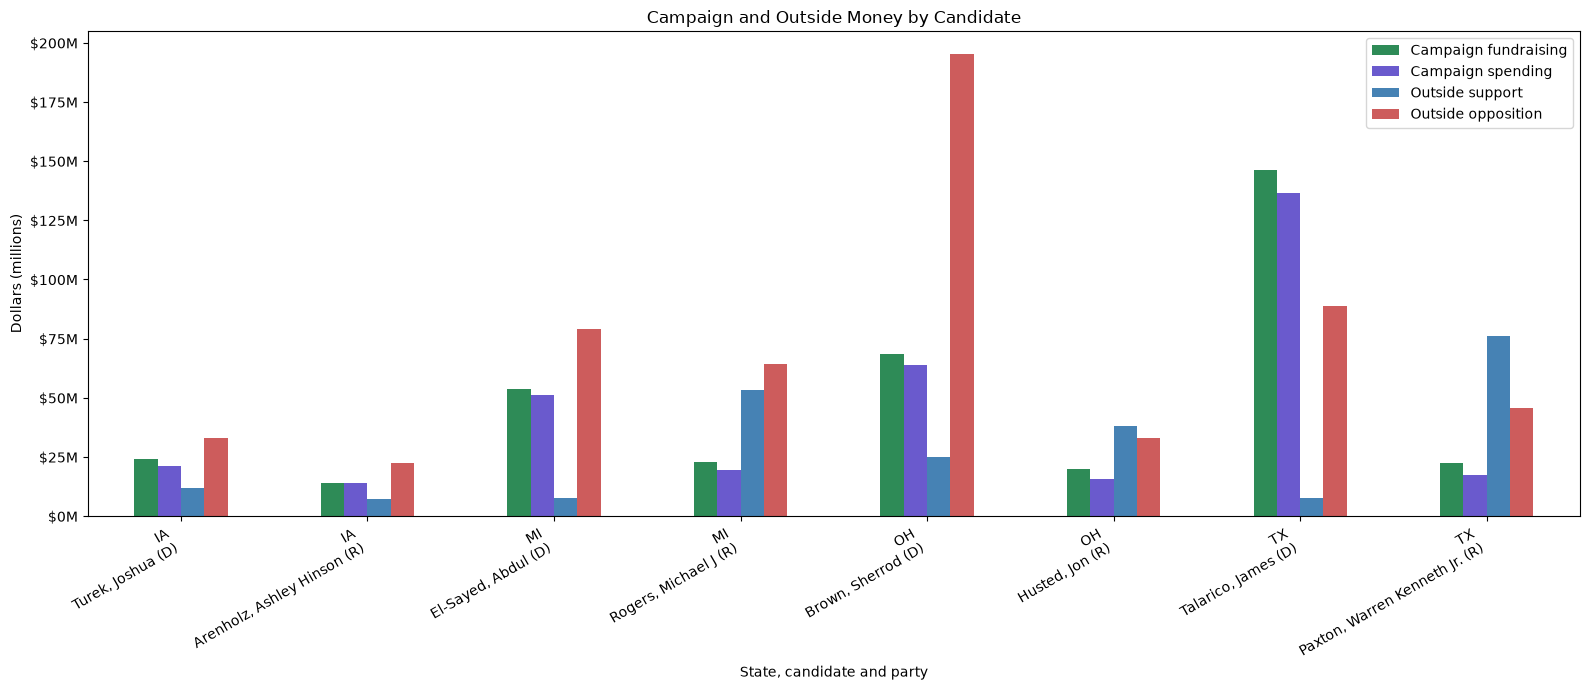

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

metrics = [
    "receipts",
    "disbursements",
    "outside_support",
    "outside_opposition"
]

chart_data = candidate_money.copy()

party_short = chart_data["party_name"].map({
    "DEMOCRATIC PARTY": "D",
    "REPUBLICAN PARTY": "R"
})

chart_data["candidate_label"] = (
    chart_data["state"]
    + "\n"
    + chart_data["candidate_name"].str.title()
    + " ("
    + party_short
    + ")"
)

chart_data[metrics] = chart_data[metrics] / 1_000_000

ax = chart_data.set_index("candidate_label")[metrics].plot(
    kind="bar",
    figsize=(16, 7),
    color=["seagreen", "slateblue", "steelblue", "indianred"]
)

ax.set_title("Campaign and Outside Money by Candidate")
ax.set_xlabel("State, candidate and party")
ax.set_ylabel("Dollars (millions)")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value:,.0f}M")
)
ax.legend([
    "Campaign fundraising",
    "Campaign spending",
    "Outside support",
    "Outside opposition"
])

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/campaign_outside_comparison.png", dpi=300)
plt.show()